<a href="https://colab.research.google.com/github/TsouLac/2026_ML_EES/blob/main/Tuto/3.1-simple-machine-learning-algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> Notebook-friendly copy of `part-II/3.1-simple-machine-learning-algorithms.ipynb`, generated by `tools/make_live.py`. Edit the book notebook, not this file.

# 3.1) Basic Machine Learning Algorithms for Classification Tasks

This week we will introduce simple ML models particularly useful for classification tasks. Classification tasks aim to automatically assign different labels to new data based on the multivariate characteristics of the training dataset. We will introduce three possible approaches for such tasks: Support Vector Machine (SVM), Random Forest (RF) and Ensemble Models. Here you find a Machine Learning Glossary : [Link](https://developers.google.com/machine-learning/glossary/#top_of_page) that defines general ML terms

**🎯 Learning objectives**

- Understand the applicability of SVMs.
- Know how to train and interpret a decision tree.
- Know how to choose a regularization hyperparameter.
- Define a RF model.
- Know some advantages or drawbacks of ensemble modeling.
- Understand feature importance.

## 3.1.1 Support Vector Machines

![SVM_cartoon.jpeg](https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/SVM_cartoon.jpeg?raw=1)
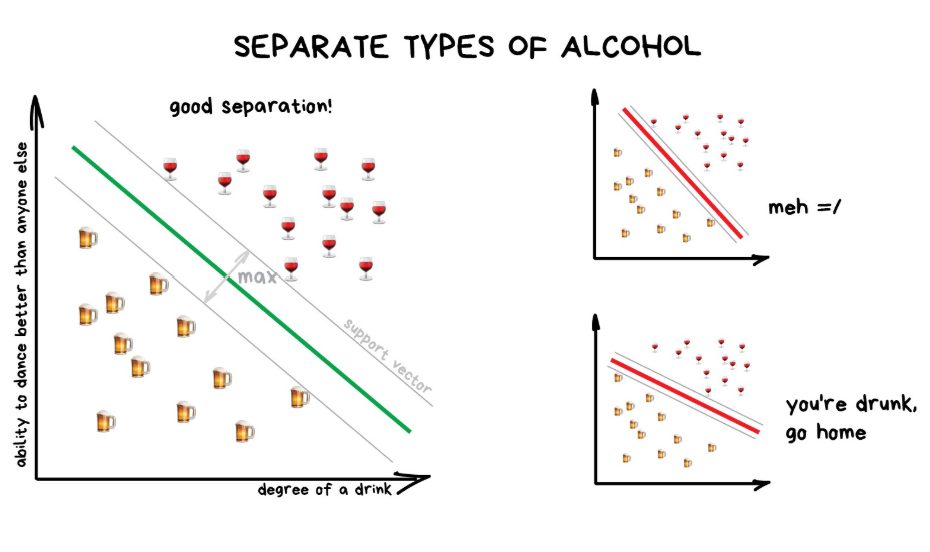

Photo credit: **Machine Learning for Everyone**, vas3k's blog. ([link](https://vas3k.com/blog/machine_learning/))

**Key points**

*   SVM aims to find the decision boundary that linearly separates two data classes in feature space. (*Hard margin classification*)

*   The *decision boundary* should maximise the distance between the boundary and the data point in each class closest to the line.

*   Hard margin classification usually results in a model that is oversensitive to outliers. Allowing margin violations over a certain region around the boundary should result in a more generalisable model. (*Soft margin classification*)

*   We use a *regularisation parameter* (C) to control the number of margin violations allowed when finding the decision boundary. Smaller C = more misclassifications.

*   For real-world data that is not linearly separable, we apply the *kernel trick*. The idea is to transform the data into linearly separable forms so that the SVM can be used.

*   Polynomial, Gaussian RBF, and Sigmoid kernels are the three kernels we will discuss in class.

*   The SVM and the decision boundary can be used in regression tasks. Margin violations should be minimised when we use SVMs for regression tasks.

**Environmental Sciences Applications**

Multiclass SVMs can be useful when your problem involves labelling different categories of data from a large dataset. One example is land cover classification from remote sensing data (e.g., B Rokni Deilmai et al 2014).

Assuming you have a large earth image dataset with satellite pictures taken from different channels and instruments, and your research task is to find the best way to classify new images into forest, desert etc automatically. The SVM can be used to find the decision boundary that best separates this multivariate dataset.

Reference:
B Rokni Deilmai et al 2014 IOP Conf. Ser.: Earth Environ. Sci. 20 012052
([Link to Paper](https://doi.org/10.1088/1755-1315/20/1/012052))

**Exercise: SVMs for flower classification**
We use scikit-learn to build different SVMs to classify flowers in the proprocessed iris dataset. You will experiment with different regularization parameters and SVM algorithms to understand how they change the classifier performance.



1.   Load the iris dataset with scikit-learn
2.   Train different SVM models on the preprocessed dataset
3.   Learn how to visualize the decision boundary with matplotlib
4.   Change regularization parameters and compare model skills

## 3.1.2 Decision Trees

Decision trees are a type of simple ML algorithm suitable for both classification and regression tasks. Decision trees are highly intuitive and interpretable since they are essentially a set of multiple decision functions. This interpretability makes decision trees useful for simple ML tasks, compared to complex neural networks that we will introduce in the upcoming weeks.

Here is an example decision tree applied to an environmental science data. The diagram is taken from Figure 1 of Gagne et al. (2009).

![decision_tree_example.gif](https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/decision_tree_example.gif?raw=1)

**Key points**

*   Decision trees comprise multiple nodes and branches. Different nodes encode decisions based on input features.

*   Scikit-learn uses the Classification And Regression Tree (CART) algorithm to divide data, create new decision nodes (growing the trees)

*   The CART algorithm finds the optimal data features and thresholds that can reduce impurity in the split samples (classification) or MSE (regression) the most. Data impurity can be measured by the Gini impurity values [(reference)](https://en.wikipedia.org/wiki/Decision_tree_learning#:~:text=Gini%20impurity%20measures%20how%20often,into%20a%20single%20target%20category.).

*   Training stops when the CART algorithm cannot find new rules to reduce impurity/entropy, or when the maximum depth (a tuneable hyperparameter) is reached.

*   Similar to SVMs, there are different regularisation hyperparameters in the scikit-learn implementation that need to be tuned to get a model that generalizes well to unseen data. (see Géron, chapter 5, for details)

*   It is particularly important to tune the regularisation hyperparameter when using decision trees since they are highly susceptible to overfitting.

* Decision trees are prone to overfitting if the model becomes overly complex

**Environmental Sciences Applications**

Decision trees can be useful when your problem when you have a multiclass classification problem. One example is to classify and differentiate types of thunderstorms from weather model outputs or weather radar images (e.g., Gagne et al 2009).

For this example, the authors measured different aspects of storm morphology (shape, size etc.), rain intensity measurements, and wind measurements. The measurements of different physical variables provide the list of features for the decision tree algorithm. The trained decision trees contain the optimal thresholds for different features that can separate different thunderstorms into pre-defined categories.


Reference:
Gagne, D., A. McGovern, and J. Brotzge, 2009: Classification of convective areas using decision trees. J. Atmos. Oceanic Technol., 26, 1341–1353
([Link to Paper](https://journals.ametsoc.org/view/journals/atot/26/7/2008jtecha1205_1.xml))

**Exercise: Train and fine tune a decision tree on a synthetic dataset**
How to find the best set of hyperparameters for a single decision tree for a dataset?

1.   Load the moons dataset and split the data into train/test sets
2.   Visualize the split data to make sure the split is done correctly
3.   Conduct hyperparameter search to find the best parameters leading to the best performing tree
4.   Compare classification accuracy

## 3.1.3 Random Forests and Ensemble Modeling

This section explores combining multiple ML models to improve the overall performance and generalizability of the ML predictions. Ensemble learning combines the predictions from a diverse set of models, which improves the robustness and trustworthiness of the ML predictions. This chapter focuses on Random Forest, an ensemble of decision trees.

**Key points**

*   The simplest ensemble model architecture is *voting classifier*. It combines several models with diverse architectures. The majority class in the classification outputs will be the output of the overall model.

*   The heterogeneity in voting classifiers is *architecture-based*. Diversity in predictions can also be achieved by using the same ML algorithm to train different models on different subsets of data.

*   There are two ways of sampling training data to create sets of ML models. They are *bagging* (with replacement) and *pasting* (without replacement).

*   Random Forest (RF) combines multiple decision trees (usually with bagging) on random subsets of training data. Random forest models allow greater tree diversity and generally make better predictions for new data.

*   To interpret RF models, scikit-learn provides a feature importance measurement, which amounts to how a specific feature reduces gini impurity amongst all trees.

*   The practice of boosting provides additional improvements in model performance and generalisation. Boosting is to train different ensemble models sequentially, with the later models specifically tasked to correct the error in the earlier trained models. *Gradient-boosting trees* are a good example of boosting for decision trees algorithms.

*   Ensemble models typically improve performance by decreasing overfitting and variance compared to decision trees.

**Environmental Sciences Applications**

Random Forests can be used in similar environmental science problems as decision trees. We provide a practical exercise of using RF for real environmental science problems, based on a recent peer-reviewed paper (Tonini et al. 2020). The problem at hand is to create a susceptibility map of wildfires in Liguria, Italy. We will provide you a dataset with various environmental data (vegetation, topography, land use etc.). With this dataset, you will try to train an ensemble classification model and create a wildfire susceptibility map.

Here is the wildfire susceptibility map in Tonini et al. (2020) that you will try to recreate in the exercise.

![RF_map.jpg](https://github.com/gse-unil/2026_MLEES_book/blob/main/live/part-II/_static/RF_map.jpg?raw=1)

Reference:
Tonini, M., D’Andrea, M., Biondi, G., Degli Esposti, S., Trucchia, A., & Fiorucci, P. (2020). A Machine Learning-Based Approach for Wildfire Susceptibility Mapping. The Case Study of the Liguria Region in Italy. Geosciences.

([Link to Paper](https://www.mdpi.com/2076-3263/10/3/105))